In [29]:
!pip -q install geopandas rasterio pyproj shapely scikit-learn openpyxl pyogrio

In [30]:

# ==========================================================
# PROJETO: RECOMENDAÇÃO AGROFLORESTAL NA CAATINGA
# Região piloto: Submédio São Francisco - BA
# Algoritmo: K-Nearest Neighbors (KNN)
# ==========================================================

import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import unicodedata
import re

from pathlib import Path
from shapely.geometry import Point
from pyproj import Transformer
from IPython.display import display

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import NearestNeighbors

# Parâmetros do algoritmo
K = 3
EPSILON = 1e-8
DISTANCIA_MAXIMA = 4.0
SEED = 42

# Variáveis utilizadas pelo KNN
FEATURES_NUMERICAS = [
    "ndvi_2025",
    "ndvi_media_historica",
    "ndvi_std_historico",
    "ndvi_tendencia"
]

FEATURES_CATEGORICAS = ["classe_solo"]

FEATURES = FEATURES_NUMERICAS + FEATURES_CATEGORICAS

NOMES_SOLUCOES = {
    "IPF": "Sistema Silvipastoril",
    "ILPF": "Sistema Agrossilvipastoril",
    "RNA": "Regeneração Natural Assistida"
}

# Localização automática dos arquivos
def localizar_arquivo(nome):

    for pasta in [Path("/content"), Path("/")]:
        caminho = pasta / nome

        if caminho.is_file():
            return caminho

    raise FileNotFoundError(f"Arquivo não encontrado: {nome}")


ARQUIVO_ROI = localizar_arquivo(
    "regiao_piloto.geojson"
)

ARQUIVO_NDVI = localizar_arquivo(
    "Features_NDVI_KNN_Submedio_SF_MODIS.tif"
)

ARQUIVO_SOLOS = localizar_arquivo(
    "Solos_Submedio_SF_KNN.gpkg"
)

ARQUIVO_EMBRAPA = localizar_arquivo(
    "Submedio_Sao_Francisco_Caracteristicas_e_Solos_Embrapa.xlsx"
)

ARQUIVO_CASOS = localizar_arquivo(
    "Casos_Referencia_Simulados.csv"
)

print("Bibliotecas importadas.")
print("Todos os arquivos foram localizados.")


Bibliotecas importadas.
Todos os arquivos foram localizados.


In [31]:

# ==========================================================
# CARREGAMENTO DOS DATASETS
# ==========================================================

def normalizar_texto(valor):

    if pd.isna(valor):
        return None

    texto = unicodedata.normalize("NFKD", str(valor))

    texto = texto.encode(
        "ASCII", "ignore"
    ).decode("ASCII")

    texto = re.sub(r"\s+", " ", texto).strip().upper()

    if texto in ["", "NONE", "NAN", "NULL", "<NA>"]:
        return None

    return texto


# Região piloto
roi = gpd.read_file(ARQUIVO_ROI).to_crs("EPSG:4326")

# Mapa pedológico
solos = gpd.read_file(
    ARQUIVO_SOLOS,
    layer="solos"
).to_crs("EPSG:4326")

# Base de referência
casos = pd.read_csv(ARQUIVO_CASOS)

# Base de conhecimento pedológico
embrapa = pd.read_excel(
    ARQUIVO_EMBRAPA,
    sheet_name="Classes_de_Solo"
)


# ==========================================================
# VALIDAÇÃO DOS DADOS
# ==========================================================

if len(roi) != 4:
    raise ValueError("Esperados quatro municípios na região piloto.")

if not roi.geometry.is_valid.all():
    raise ValueError("Geometrias inválidas na região piloto.")

if solos.empty or not solos.geometry.is_valid.all():
    raise ValueError("Mapa de solos vazio ou com geometrias inválidas.")

if "classe_solo" not in solos.columns:
    raise ValueError("Coluna classe_solo não encontrada.")

colunas_obrigatorias = FEATURES + [
    "id_caso",
    "solucao",
    "tipo_dado",
    "nome_solucao"
]

faltantes = set(colunas_obrigatorias) - set(casos.columns)

if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

if casos[colunas_obrigatorias].isna().any().any():
    raise ValueError("Existem valores ausentes nos casos.")

if casos["id_caso"].duplicated().any():
    raise ValueError("Identificadores duplicados.")

if len(casos) != 12:
    raise ValueError("Esperados 12 cenários de referência.")

casos["tipo_dado"] = casos["tipo_dado"].map(normalizar_texto)

if not casos["tipo_dado"].eq("SINTETICO").all():
    raise ValueError("A base deve estar identificada como sintética.")

casos["solucao"] = casos["solucao"].map(normalizar_texto)

if not casos["solucao"].isin(NOMES_SOLUCOES).all():
    raise ValueError("Solução desconhecida na base.")

for coluna in FEATURES_NUMERICAS:
    casos[coluna] = pd.to_numeric(
        casos[coluna],
        errors="raise"
    )

if not np.isfinite(casos[FEATURES_NUMERICAS].to_numpy()).all():
    raise ValueError("Valores numéricos inválidos.")

if not casos[FEATURES_NUMERICAS[:2]].apply(
    lambda s: s.between(-1, 1)
).all().all():
    raise ValueError("NDVI fora do intervalo esperado.")

if casos["ndvi_std_historico"].lt(0).any():
    raise ValueError("Desvio padrão negativo.")

# Padronização das categorias
casos["classe_solo"] = casos["classe_solo"].map(normalizar_texto)

solos["classe_solo"] = solos["classe_solo"].map(normalizar_texto)

if casos["classe_solo"].isna().any():
    raise ValueError("Classes de referência ausentes.")

# Validação do raster
with rasterio.open(ARQUIVO_NDVI) as src:

    if src.count != 4:
        raise ValueError("O raster deve conter quatro bandas.")

    if src.crs is None:
        raise ValueError("Raster sem sistema de coordenadas.")

    print("CRS do raster:", src.crs)
    print("Quantidade de bandas:", src.count)
    print("Dimensões:", src.width, "x", src.height)
    print("NoData:", src.nodata)

print("\nMunicípios:", len(roi))
print("Unidades pedológicas:", len(solos))
print("Cenários sintéticos:", len(casos))
print("Variáveis do KNN:", len(FEATURES))

print("\nDistribuição das soluções:")
print(casos["solucao"].value_counts())

print("\nColunas da planilha Embrapa:")
print(embrapa.columns.tolist())

display(casos)


CRS do raster: PROJCS["MODIS Sinusoidal",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Quantidade de bandas: 4
Dimensões: 1320 x 676
NoData: -9999.0

Municípios: 4
Unidades pedológicas: 261
Cenários sintéticos: 12
Variáveis do KNN: 5

Distribuição das soluções:
solucao
IPF     4
ILPF    4
RNA     4
Name: count, dtype: int64

Colunas da planilha Embrapa:
['CLASSES DE SOLO PREDOMINANTES — SUBMÉDIO SÃO FRANCISCO (EMBRAPA SOLOS / SiBCS)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']


,id_caso,ndvi_2025,ndvi_media_historica,ndvi_std_historico,ndvi_tendencia,classe_solo,solucao,tipo_dado,nome_solucao
0,IPF01,0.30,0.34,0.05,-0.015,LUVISSOLO,IPF,SINTETICO,Sistema Silvipastoril
1,IPF02,0.35,0.38,0.06,-0.012,ARGISSOLO,IPF,SINTETICO,Sistema Silvipastoril
2,IPF03,0.28,0.32,0.04,-0.018,NEOSSOLO LITOLICO,IPF,SINTETICO,Sistema Silvipastoril
3,IPF04,0.33,0.36,0.05,-0.010,CAMBISSOLO,IPF,SINTETICO,Sistema Silvipastoril
4,ILPF01,0.40,0.43,0.05,-0.008,LUVISSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
5,ILPF02,0.42,0.45,0.04,-0.010,LATOSSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
6,ILPF03,0.38,0.41,0.06,-0.012,ARGISSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
7,ILPF04,0.36,0.40,0.05,-0.015,VERTISSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
8,RNA01,0.19,0.27,0.08,-0.035,NEOSSOLO LITOLICO,RNA,SINTETICO,Regeneração Natural Assistida
9,RNA02,0.21,0.29,0.09,-0.030,NEOSSOLO QUARTZARENICO,RNA,SINTETICO,Regeneração Natural Assistida


In [32]:

# ==========================================================
# PROCESSAMENTO GEoesPACIAL
# ==========================================================

def validar_coordenadas(latitude, longitude):

    try:
        latitude = float(latitude)
        longitude = float(longitude)
    except (ValueError, TypeError):
        raise ValueError("As coordenadas devem ser numéricas.")

    if not np.isfinite([latitude, longitude]).all():
        raise ValueError("Coordenadas inválidas.")

    if not -90 <= latitude <= 90:
        raise ValueError("Latitude inválida.")

    if not -180 <= longitude <= 180:
        raise ValueError("Longitude inválida.")

    return latitude, longitude


def identificar_municipio(latitude, longitude):

    latitude, longitude = validar_coordenadas(
        latitude, longitude
    )

    ponto = Point(longitude, latitude)

    resultado = roi[roi.geometry.covers(ponto)]

    if resultado.empty:
        raise ValueError(
            "A localização está fora da região piloto."
        )

    if "ADM2_NAME" in resultado.columns:

        nomes = resultado["ADM2_NAME"].dropna().unique()

        if len(nomes):
            return " / ".join(map(str, nomes))

    return "Município não identificado"


def validar_ndvi(valores):

    valores = np.ma.asarray(
        valores, dtype=float
    ).filled(np.nan)

    if valores.size != 4:
        raise ValueError("Quantidade incorreta de features.")

    if not np.isfinite(valores).all():
        raise ValueError("Pixel com dados ausentes ou inválidos.")

    if np.any(valores == -9999):
        raise ValueError("Pixel com NoData.")

    if np.any(np.abs(valores[:2]) > 1):
        raise ValueError("NDVI fora do intervalo válido.")

    if valores[2] < 0:
        raise ValueError("Desvio padrão inválido.")

    return dict(zip(FEATURES_NUMERICAS, valores))


def extrair_ndvi(latitude, longitude):

    with rasterio.open(ARQUIVO_NDVI) as src:

        transformador = Transformer.from_crs(
            "EPSG:4326",
            src.crs,
            always_xy=True
        )

        x, y = transformador.transform(
            longitude, latitude
        )

        linha, coluna = src.index(x, y)

        if not (
            0 <= linha < src.height
            and 0 <= coluna < src.width
        ):
            raise ValueError("Coordenada fora do raster.")

        valores = next(
            src.sample(
                [(x, y)],
                masked=True
            )
        )

        return validar_ndvi(valores)


def identificar_solo(latitude, longitude):

    ponto = Point(longitude, latitude)

    resultado = solos[
        solos.geometry.covers(ponto)
    ]

    if resultado.empty:
        raise ValueError("Nenhuma unidade de solo encontrada.")

    if resultado["classe_solo"].isna().any():
        raise ValueError("Classe de solo não identificada.")

    classes = resultado["classe_solo"].unique()

    if len(classes) != 1:
        raise ValueError(
            "A localização possui classificação pedológica ambígua."
        )

    return classes[0]


def extrair_caracteristicas(latitude, longitude):

    latitude, longitude = validar_coordenadas(
        latitude, longitude
    )

    municipio = identificar_municipio(
        latitude, longitude
    )

    dados = extrair_ndvi(
        latitude, longitude
    )

    dados["classe_solo"] = identificar_solo(
        latitude, longitude
    )

    dados["municipio"] = municipio
    dados["latitude"] = latitude
    dados["longitude"] = longitude

    return dados


print("Funções geoespaciais implementadas.")


Funções geoespaciais implementadas.


In [33]:


# ==========================================================
# PRÉ-PROCESSAMENTO E PONDERAÇÃO DAS FEATURES
# ==========================================================

PESO_NDVI = 1.0
PESO_SOLO = 2.0

X = casos[FEATURES].copy()

preprocessador = ColumnTransformer(

    transformers=[
        (
            "numericas",
            StandardScaler(),
            FEATURES_NUMERICAS
        ),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="error"),
            FEATURES_CATEGORICAS
        )
    ],

    transformer_weights={
        "numericas": PESO_NDVI,
        "categoricas": PESO_SOLO
    },

    remainder="drop"
)

X_transformado = preprocessador.fit_transform(X)

categorias_conhecidas = set(
    casos["classe_solo"].unique()
)

print("Pré-processamento concluído.")
print("Fator do NDVI:", PESO_NDVI)
print("Fator do solo:", PESO_SOLO)
print("Shape original:", X.shape)
print("Shape transformado:", X_transformado.shape)

print("\nFeatures transformadas:")
print(preprocessador.get_feature_names_out())



Pré-processamento concluído.
Fator do NDVI: 1.0
Fator do solo: 2.0
Shape original: (12, 5)
Shape transformado: (12, 12)

Features transformadas:
['numericas__ndvi_2025' 'numericas__ndvi_media_historica'
 'numericas__ndvi_std_historico' 'numericas__ndvi_tendencia'
 'categoricas__classe_solo_ARGISSOLO'
 'categoricas__classe_solo_CAMBISSOLO'
 'categoricas__classe_solo_LATOSSOLO' 'categoricas__classe_solo_LUVISSOLO'
 'categoricas__classe_solo_NEOSSOLO LITOLICO'
 'categoricas__classe_solo_NEOSSOLO QUARTZARENICO'
 'categoricas__classe_solo_PLANOSSOLO'
 'categoricas__classe_solo_VERTISSOLO']


In [34]:

# ==========================================================
# MOTOR DE SIMILARIDADE - KNN
# ==========================================================

modelo_knn = NearestNeighbors(

    n_neighbors=K,
    metric="euclidean",
    algorithm="brute"

)

modelo_knn.fit(X_transformado)


def buscar_vizinhos(caracteristicas):

    classe = caracteristicas["classe_solo"]

    if classe not in categorias_conhecidas:
        raise ValueError(
            f"Não existem referências para o solo: {classe}"
        )

    consulta = pd.DataFrame(
        [caracteristicas]
    )[FEATURES]

    consulta_transformada = preprocessador.transform(
        consulta
    )

    distancias, indices = modelo_knn.kneighbors(
        consulta_transformada
    )

    vizinhos = casos.iloc[
        indices[0]
    ].copy().reset_index(drop=True)

    vizinhos["distancia"] = distancias[0]

    return vizinhos


print("Modelo KNN inicializado.")
print("Número de vizinhos:", K)
print("Métrica: distância euclidiana")
print("Casos de referência:", len(X))


Modelo KNN inicializado.
Número de vizinhos: 3
Métrica: distância euclidiana
Casos de referência: 12


In [35]:

# ==========================================================
# PONDERAÇÃO E RANKING DAS SOLUÇÕES
# ==========================================================

def calcular_ranking(vizinhos):

    vizinhos = vizinhos.copy()

    distancias = vizinhos["distancia"].to_numpy()

    elegiveis = distancias <= DISTANCIA_MAXIMA

    pesos = np.zeros(len(vizinhos))

    # Tratamento de correspondências exatas
    coincidentes = np.isclose(
        distancias, 0,
        atol=EPSILON,
        rtol=0
    )

    if coincidentes.any():

        pesos[coincidentes] = 1.0

    else:

        pesos[elegiveis] = (
            1 / (distancias[elegiveis] + EPSILON)
        )

    vizinhos["peso"] = pesos

    if pesos.sum() == 0:
        return vizinhos, pd.DataFrame(
            columns=["solucao", "pontuacao", "percentual"]
        )

    ranking = (
        vizinhos[vizinhos["peso"] > 0]
        .groupby("solucao", as_index=False)["peso"]
        .sum()
        .rename(columns={"peso": "pontuacao"})
    )

    ranking["percentual"] = (
        ranking["pontuacao"]
        / ranking["pontuacao"].sum()
        * 100
    )

    ranking["nome_solucao"] = ranking["solucao"].map(
        NOMES_SOLUCOES
    )

    ranking = ranking.sort_values(
        ["percentual", "solucao"],
        ascending=[False, True]
    ).reset_index(drop=True)

    return vizinhos, ranking


print("Sistema de ranking implementado.")


Sistema de ranking implementado.


In [36]:

# ==========================================================
# CÉLULA 8 - INTEGRAÇÃO DA BASE PEDOLÓGICA DA EMBRAPA
# ==========================================================

# 1. Leitura com o cabeçalho correto
embrapa = pd.read_excel(
    ARQUIVO_EMBRAPA,
    sheet_name="Classes_de_Solo",
    header=3
)

embrapa.columns = embrapa.columns.astype(str).str.strip()

COLUNA_SOLO = "Classe de Solo (SiBCS)"

# 2. Dicionário de correspondência IBGE - Embrapa
MAPEAMENTO_SOLOS = {
    "LATOSSOLOS": "LATOSSOLO",
    "ARGISSOLOS": "ARGISSOLO",
    "CAMBISSOLOS": "CAMBISSOLO",
    "VERTISSOLOS": "VERTISSOLO",
    "LUVISSOLOS": "LUVISSOLO",
    "PLANOSSOLOS": "PLANOSSOLO",
    "NEOSSOLOS LITOLICOS": "NEOSSOLO LITOLICO",
    "NEOSSOLOS FLUVICOS": "NEOSSOLO FLUVICO",
    "NEOSSOLOS QUARTZARENICOS": "NEOSSOLO QUARTZARENICO"
}

# 3. Normalização das classes
embrapa["classe_normalizada"] = (
    embrapa[COLUNA_SOLO]
    .map(normalizar_texto)
    .str.replace(r"\s*\([^)]*\)", "", regex=True)
    .str.strip()
    .map(MAPEAMENTO_SOLOS)
)

# Remove títulos, resumos, notas e linhas vazias
embrapa = embrapa.dropna(
    subset=["classe_normalizada"]
).reset_index(drop=True)


# 4. Função de consulta pedológica
def consultar_embrapa(classe_solo):

    classe = normalizar_texto(classe_solo)

    resultado = embrapa[
        embrapa["classe_normalizada"] == classe
    ]

    if len(resultado) != 1:
        return None

    return (
        resultado.iloc[0]
        .drop("classe_normalizada")
        .dropna()
        .to_dict()
    )


# 5. Função de apresentação
def exibir_conhecimento_pedologico(classe_solo):

    conhecimento = consultar_embrapa(classe_solo)

    print("\n" + "=" * 65)
    print("CONHECIMENTO PEDOLÓGICO - EMBRAPA")
    print("=" * 65)

    if conhecimento is None:

        print(
            "Classe sem correspondência na base Embrapa."
        )

        return

    for atributo, valor in conhecimento.items():

        print(f"\n{atributo}:")
        print(valor)


# 6. Validação da integração
print("Classes pedológicas integradas:", len(embrapa))

display(
    embrapa[
        [COLUNA_SOLO, "classe_normalizada"]
    ]
)

print("\nIntegração pedológica concluída.")


Classes pedológicas integradas: 9


,Classe de Solo (SiBCS),classe_normalizada
0,Latossolos (Vermelhos e Vermelho-Amarelos),LATOSSOLO
1,Argissolos (Vermelho-Amarelos e Amarelos),ARGISSOLO
2,Cambissolos (Háplicos),CAMBISSOLO
3,Neossolos Flúvicos,NEOSSOLO FLUVICO
4,Vertissolos (Háplicos e Ebânicos),VERTISSOLO
5,Luvissolos (Crômicos),LUVISSOLO
6,Planossolos (Háplicos e Nátricos),PLANOSSOLO
7,Neossolos Quartzarênicos,NEOSSOLO QUARTZARENICO
8,Neossolos Litólicos,NEOSSOLO LITOLICO



Integração pedológica concluída.


In [37]:
exibir_conhecimento_pedologico("VERTISSOLO")


CONHECIMENTO PEDOLÓGICO - EMBRAPA

Classe de Solo (SiBCS):
Vertissolos (Háplicos e Ebânicos)

Textura Predominante:
Muito argilosa (argilas expansivas 2:1)

Profundidade Efetiva:
Moderadamente profundos (80–120 cm)

Fertilidade Natural:
Muito Alta (eutróficos, elevada CTC)

Drenagem Interna:
Imperfeita a mal drenados

Risco de Degradação:
Alto

Principais Vulnerabilidades:
Fendas profundas na seca e alta plasticidade/pegajosidade na chuva; risco acentuado de salinização sob irrigação.

Ocorrência Típica no Recorte:
Manchas expressivas em Juazeiro (projetos Mandacaru, Tourão e baixo Salitre).

Aptidão e Manejo Recomendado:
Mecanização restrita à faixa ideal de umidade; bom potencial para fruticultura, cana e forrageiras com drenagem controlada e cultivo mínimo.


In [38]:

# ==========================================================
# SISTEMA DE RECOMENDAÇÃO AGROFLORESTAL
# ==========================================================

def recomendar(latitude, longitude, visualizar=True):

    caracteristicas = extrair_caracteristicas(
        latitude, longitude
    )

    vizinhos = buscar_vizinhos(
        caracteristicas
    )

    vizinhos, ranking = calcular_ranking(
        vizinhos
    )

    print("=" * 65)
    print("SISTEMA DE RECOMENDAÇÃO AGROFLORESTAL")
    print("CAATINGA - SUBMÉDIO SÃO FRANCISCO")
    print("=" * 65)

    print("\nLOCALIZAÇÃO CONSULTADA")

    print("Latitude:", caracteristicas["latitude"])
    print("Longitude:", caracteristicas["longitude"])
    print("Município:", caracteristicas["municipio"])
    print("Classe de solo:", caracteristicas["classe_solo"])

    print("\nCARACTERÍSTICAS AMBIENTAIS")

    for feature in FEATURES_NUMERICAS:

        valor = caracteristicas[feature]

        print(f"{feature}: {valor:.4f}")

    print("\nVIZINHOS MAIS PRÓXIMOS")

    display(
        vizinhos[
            [
                "id_caso",
                "classe_solo",
                "solucao",
                "distancia",
                "peso"
            ]
        ].round(4)
    )

    resultado = {

        "caracteristicas": caracteristicas,
        "vizinhos": vizinhos,
        "ranking": ranking,
        "recomendacao": None

    }

    if ranking.empty:

        print(
            "\nNão existem referências suficientemente "
            "semelhantes segundo o limiar configurado."
        )

        return resultado

    maior_pontuacao = ranking.iloc[0]["percentual"]

    melhores = ranking[
        np.isclose(
            ranking["percentual"],
            maior_pontuacao
        )
    ]

    recomendacao = " / ".join(
        melhores["nome_solucao"].tolist()
    )

    resultado["recomendacao"] = recomendacao

    print("\nRANKING DAS SOLUÇÕES")

    display(
        ranking[
            ["nome_solucao", "percentual"]
        ].round(2)
    )

    print("\n" + "=" * 65)
    print("SOLUÇÃO CANDIDATA:")
    print(recomendacao.upper())
    print("=" * 65)

    if len(melhores) > 1:
        print("Houve empate entre as soluções.")

    print(
        f"Pontuação relativa: {maior_pontuacao:.2f}%"
    )

    print(
        f"Distância do vizinho mais próximo: "
        f"{vizinhos['distancia'].min():.4f}"
    )

    print("\nJUSTIFICATIVA")

    print(
        "A solução candidata foi selecionada por "
        "similaridade entre as características "
        "ambientais da localização consultada e "
        "os cenários sintéticos de referência."
    )

    exibir_conhecimento_pedologico(
        caracteristicas["classe_solo"]
    )

    if visualizar:

        fig, ax = plt.subplots(
            figsize=(10, 4.5)
        )

        barras = ax.barh(
            ranking["nome_solucao"],
            ranking["percentual"],
            color="#52835C"
        )

        ax.invert_yaxis()

        ax.set_xlim(0, 110)

        ax.bar_label(
            barras,
            fmt="%.2f%%",
            padding=5
        )

        ax.set_title(
            "Ranking de Similaridade Agroflorestal",
            fontsize=15,
            fontweight="bold"
        )

        ax.set_xlabel(
            "Pontuação relativa (%)"
        )

        ax.grid(
            axis="x",
            alpha=0.2
        )

        plt.tight_layout()
        plt.show()

    print("\nLIMITAÇÕES")
    print("- Base de referência sintética.")
    print("- Protótipo não validado agronomicamente.")
    print("- Pontuação não representa probabilidade de sucesso.")
    print("- NDVI não comprova degradação isoladamente.")
    print("- O mapa de solos possui escala regional.")
    print("- A intervenção requer avaliação técnica.")

    return resultado


print("Sistema de recomendação implementado.")


Sistema de recomendação implementado.


In [39]:

# ==========================================================
# TESTES FUNCIONAIS
# ==========================================================

def testar_erro(funcao, *args):

    try:
        funcao(*args)
    except ValueError:
        return True

    return False


# Teste 1 - Latitude inválida
assert testar_erro(
    validar_coordenadas, 100, -40
)

# Teste 2 - Longitude inválida
assert testar_erro(
    validar_coordenadas, -9, 200
)

# Teste 3 - Coordenadas não numéricas
assert testar_erro(
    validar_coordenadas, "abc", -40
)

# Teste 4 - Coordenadas fora da região piloto
assert testar_erro(
    identificar_municipio, 0, 0
)

# Teste 5 - NDVI ausente
assert testar_erro(
    validar_ndvi,
    [0.30, np.nan, 0.05, -0.01]
)

# Teste 6 - NoData
assert testar_erro(
    validar_ndvi,
    [-9999, 0.30, 0.05, -0.01]
)

# Teste 7 - Categoria desconhecida
consulta_teste = casos.iloc[0][FEATURES].to_dict()

consulta_teste["classe_solo"] = "DESCONHECIDO"

assert testar_erro(
    buscar_vizinhos,
    consulta_teste
)

# Teste 8 - Correspondência exata
consulta_exata = casos.iloc[0][FEATURES].to_dict()

vizinhos_teste = buscar_vizinhos(consulta_exata)

assert np.isclose(
    vizinhos_teste["distancia"].min(),
    0
)

_, ranking_teste = calcular_ranking(vizinhos_teste)

assert np.isclose(
    ranking_teste["percentual"].sum(),
    100
)

assert ranking_teste.iloc[0]["solucao"] == casos.iloc[0]["solucao"]

# Teste 9 - Ausência de vizinhos suficientemente próximos
vizinhos_distantes = vizinhos_teste.copy()

vizinhos_distantes["distancia"] = DISTANCIA_MAXIMA + 1

_, ranking_distante = calcular_ranking(vizinhos_distantes)

assert ranking_distante.empty

# Teste 10 - Vetor de características válido
features_teste = validar_ndvi(
    [0.30, 0.34, 0.05, -0.015]
)

assert list(features_teste.keys()) == FEATURES_NUMERICAS

print("=" * 55)
print("TODOS OS 10 TESTES ASSERTIVOS PASSARAM.")
print("=" * 55)


TODOS OS 10 TESTES ASSERTIVOS PASSARAM.


Ponto de demonstração encontrado.
Latitude: -9.87130386024202
Longitude: -40.46375982422032
SISTEMA DE RECOMENDAÇÃO AGROFLORESTAL
CAATINGA - SUBMÉDIO SÃO FRANCISCO

LOCALIZAÇÃO CONSULTADA
Latitude: -9.87130386024202
Longitude: -40.46375982422032
Município: Juazeiro
Classe de solo: NEOSSOLO LITOLICO

CARACTERÍSTICAS AMBIENTAIS
ndvi_2025: 0.2253
ndvi_media_historica: 0.2793
ndvi_std_historico: 0.0368
ndvi_tendencia: -0.0042

VIZINHOS MAIS PRÓXIMOS


,id_caso,classe_solo,solucao,distancia,peso
0,IPF03,NEOSSOLO LITOLICO,IPF,1.9157,0.5220
1,IPF01,LUVISSOLO,IPF,3.5330,0.2830
2,IPF04,CAMBISSOLO,IPF,3.6455,0.2743



RANKING DAS SOLUÇÕES


,nome_solucao,percentual
0,Sistema Silvipastoril,100.0



SOLUÇÃO CANDIDATA:
SISTEMA SILVIPASTORIL
Pontuação relativa: 100.00%
Distância do vizinho mais próximo: 1.9157

JUSTIFICATIVA
A solução candidata foi selecionada por similaridade entre as características ambientais da localização consultada e os cenários sintéticos de referência.

CONHECIMENTO PEDOLÓGICO - EMBRAPA

Classe de Solo (SiBCS):
Neossolos Litólicos

Textura Predominante:
Variável (arenosa a média), com elevada pedregosidade e afloramentos rochosos

Profundidade Efetiva:
Muito rasos (< 50 cm sobre rocha)

Fertilidade Natural:
Variável (limitada pelo reduzido volume de solo)

Drenagem Interna:
Imperfeita a moderada (barrada pela rocha)

Risco de Degradação:
Muito Alto

Principais Vulnerabilidades:
Erosão severa, déficit hídrico extremo e processo de desertificação rapidamente irreversível após desmatamento.

Ocorrência Típica no Recorte:
Serras, morros residuais e pediplanos cristalinos (Curaçá, Sobradinho, Casa Nova e Juazeiro).

Aptidão e Manejo Recomendado:
Inaptos para lav

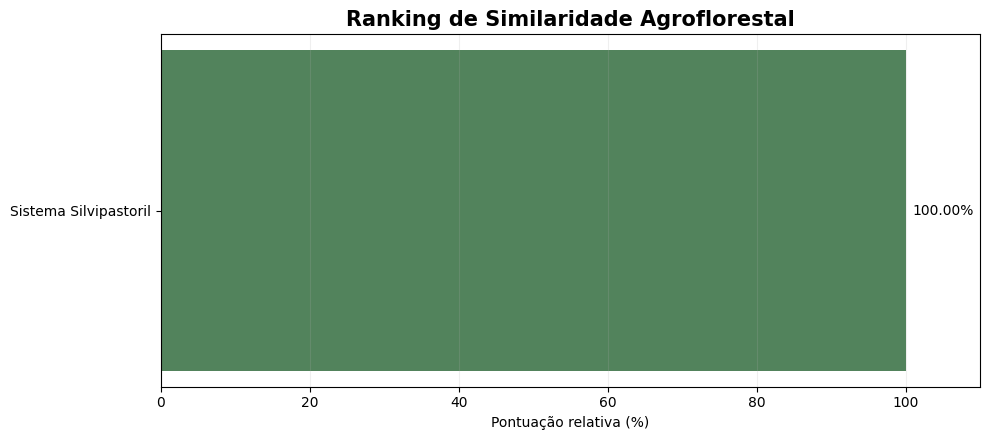


LIMITAÇÕES
- Base de referência sintética.
- Protótipo não validado agronomicamente.
- Pontuação não representa probabilidade de sucesso.
- NDVI não comprova degradação isoladamente.
- O mapa de solos possui escala regional.
- A intervenção requer avaliação técnica.


In [40]:

# ==========================================================
# LOCALIZAÇÃO AUTOMÁTICA DE UM PONTO DE TESTE
# ==========================================================

def localizar_ponto_teste(max_tentativas=500):

    rng = np.random.default_rng(SEED)

    solos_validos = solos[
        solos["classe_solo"].isin(
            categorias_conhecidas
        )
    ]

    def ponto_adequado(latitude, longitude):

        try:

            dados = extrair_caracteristicas(
                latitude, longitude
            )

            vizinhos = buscar_vizinhos(dados)

            return (
                vizinhos["distancia"].min()
                <= DISTANCIA_MAXIMA
            )

        except ValueError:

            return False

    # Primeiro testa pontos internos dos polígonos
    for geometria in solos_validos.geometry:

        ponto = geometria.representative_point()

        if ponto_adequado(ponto.y, ponto.x):
            return ponto.y, ponto.x

    # Alternativa: amostragem espacial
    minx, miny, maxx, maxy = roi.total_bounds

    for _ in range(max_tentativas):

        longitude = rng.uniform(minx, maxx)
        latitude = rng.uniform(miny, maxy)

        if ponto_adequado(latitude, longitude):
            return latitude, longitude

    raise RuntimeError(
        "Nenhum ponto adequado foi encontrado "
        "com os parâmetros atuais."
    )


latitude_teste, longitude_teste = localizar_ponto_teste()

print("Ponto de demonstração encontrado.")

print("Latitude:", latitude_teste)
print("Longitude:", longitude_teste)

resultado_teste = recomendar(
    latitude_teste,
    longitude_teste
)


CAATINGA - AGROFORESTRY RECOMMENDER
Protótipo de Inteligência Artificial
K-Nearest Neighbors | Scikit-Learn

Digite a latitude: -9.6500
Digite a longitude: -40.3500
SISTEMA DE RECOMENDAÇÃO AGROFLORESTAL
CAATINGA - SUBMÉDIO SÃO FRANCISCO

LOCALIZAÇÃO CONSULTADA
Latitude: -9.65
Longitude: -40.35
Município: Juazeiro
Classe de solo: VERTISSOLO

CARACTERÍSTICAS AMBIENTAIS
ndvi_2025: 0.2088
ndvi_media_historica: 0.2546
ndvi_std_historico: 0.0302
ndvi_tendencia: -0.0118

VIZINHOS MAIS PRÓXIMOS


,id_caso,classe_solo,solucao,distancia,peso
0,IPF03,NEOSSOLO LITOLICO,IPF,3.3508,0.2984
1,ILPF04,VERTISSOLO,ILPF,3.5801,0.2793
2,IPF01,LUVISSOLO,IPF,3.6908,0.2709



RANKING DAS SOLUÇÕES


,nome_solucao,percentual
0,Sistema Silvipastoril,67.09
1,Sistema Agrossilvipastoril,32.91



SOLUÇÃO CANDIDATA:
SISTEMA SILVIPASTORIL
Pontuação relativa: 67.09%
Distância do vizinho mais próximo: 3.3508

JUSTIFICATIVA
A solução candidata foi selecionada por similaridade entre as características ambientais da localização consultada e os cenários sintéticos de referência.

CONHECIMENTO PEDOLÓGICO - EMBRAPA

Classe de Solo (SiBCS):
Vertissolos (Háplicos e Ebânicos)

Textura Predominante:
Muito argilosa (argilas expansivas 2:1)

Profundidade Efetiva:
Moderadamente profundos (80–120 cm)

Fertilidade Natural:
Muito Alta (eutróficos, elevada CTC)

Drenagem Interna:
Imperfeita a mal drenados

Risco de Degradação:
Alto

Principais Vulnerabilidades:
Fendas profundas na seca e alta plasticidade/pegajosidade na chuva; risco acentuado de salinização sob irrigação.

Ocorrência Típica no Recorte:
Manchas expressivas em Juazeiro (projetos Mandacaru, Tourão e baixo Salitre).

Aptidão e Manejo Recomendado:
Mecanização restrita à faixa ideal de umidade; bom potencial para fruticultura, cana e f

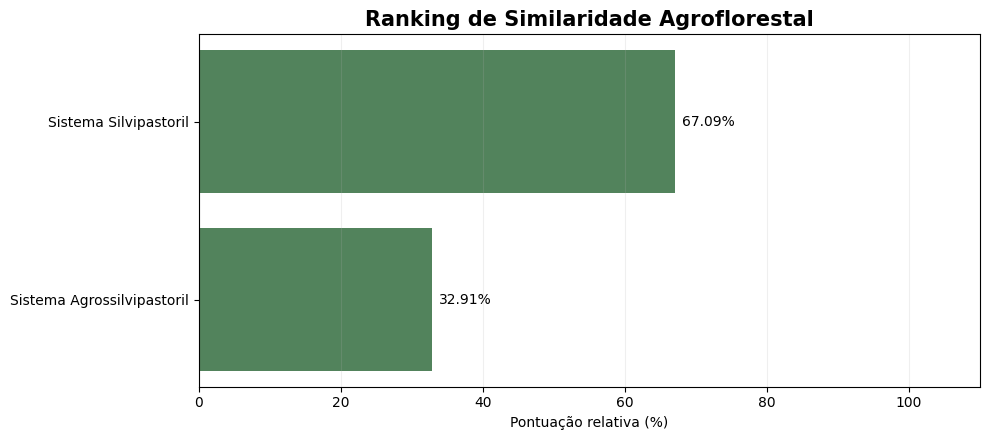


LIMITAÇÕES
- Base de referência sintética.
- Protótipo não validado agronomicamente.
- Pontuação não representa probabilidade de sucesso.
- NDVI não comprova degradação isoladamente.
- O mapa de solos possui escala regional.
- A intervenção requer avaliação técnica.


In [41]:

# ==========================================================
# EXECUÇÃO INTERATIVA
# ==========================================================

print("=" * 60)
print("CAATINGA - AGROFORESTRY RECOMMENDER")
print("Protótipo de Inteligência Artificial")
print("K-Nearest Neighbors | Scikit-Learn")
print("=" * 60)

try:

    latitude = input(
        "\nDigite a latitude: "
    ).strip().replace(",", ".")

    longitude = input(
        "Digite a longitude: "
    ).strip().replace(",", ".")

    latitude, longitude = validar_coordenadas(
        latitude, longitude
    )

    resultado = recomendar(
        latitude,
        longitude
    )

except ValueError as erro:

    print("\nRECOMENDAÇÃO INDISPONÍVEL")
    print("Motivo:", erro)


In [44]:

# ==========================================================
# VALIDAÇÃO FUNCIONAL FINAL - REGIÃO PILOTO
# ==========================================================

resultados_finais = []

for _, municipio in roi.iterrows():

    ponto = municipio.geometry.representative_point()

    latitude = ponto.y
    longitude = ponto.x

    registro = {
        "municipio": municipio["ADM2_NAME"],
        "latitude": latitude,
        "longitude": longitude
    }

    try:

        dados = extrair_caracteristicas(
            latitude, longitude
        )

        vizinhos = buscar_vizinhos(dados)

        vizinhos, ranking = calcular_ranking(vizinhos)

        registro.update({
            "classe_solo": dados["classe_solo"],
            "ndvi_2025": dados["ndvi_2025"],
            "ndvi_tendencia": dados["ndvi_tendencia"],
            "menor_distancia": vizinhos["distancia"].min()
        })

        if not ranking.empty:

            registro.update({
                "recomendacao": ranking.iloc[0]["nome_solucao"],
                "pontuacao_relativa": ranking.iloc[0]["percentual"],
                "status": "Recomendação gerada"
            })

        else:

            registro["status"] = "Similaridade insuficiente"

    except ValueError as erro:

        registro["status"] = str(erro)

    resultados_finais.append(registro)

df_validacao = pd.DataFrame(resultados_finais)

display(df_validacao.round(4))

print("\nResumo dos testes:")
print(df_validacao["status"].value_counts())


,municipio,latitude,longitude,classe_solo,ndvi_2025,ndvi_tendencia,menor_distancia,recomendacao,pontuacao_relativa,status
0,Casa Nova,-9.2365,-41.2622,LATOSSOLO,0.4162,-0.0070,1.1334,Sistema Agrossilvipastoril,100.0000,Recomendação gerada
1,Curaca,-9.2355,-39.6162,CAMBISSOLO,0.2848,-0.0127,1.7088,Sistema Silvipastoril,60.5782,Recomendação gerada
2,Juazeiro,-9.4800,-40.2427,PLANOSSOLO,0.3083,-0.0199,3.0041,Sistema Silvipastoril,66.0504,Recomendação gerada
3,Sobradinho,-9.6394,-40.8811,ARGISSOLO,0.4712,0.0244,4.5445,NaN,NaN,Similaridade insuficiente



Resumo dos testes:
status
Recomendação gerada          3
Similaridade insuficiente    1
Name: count, dtype: int64


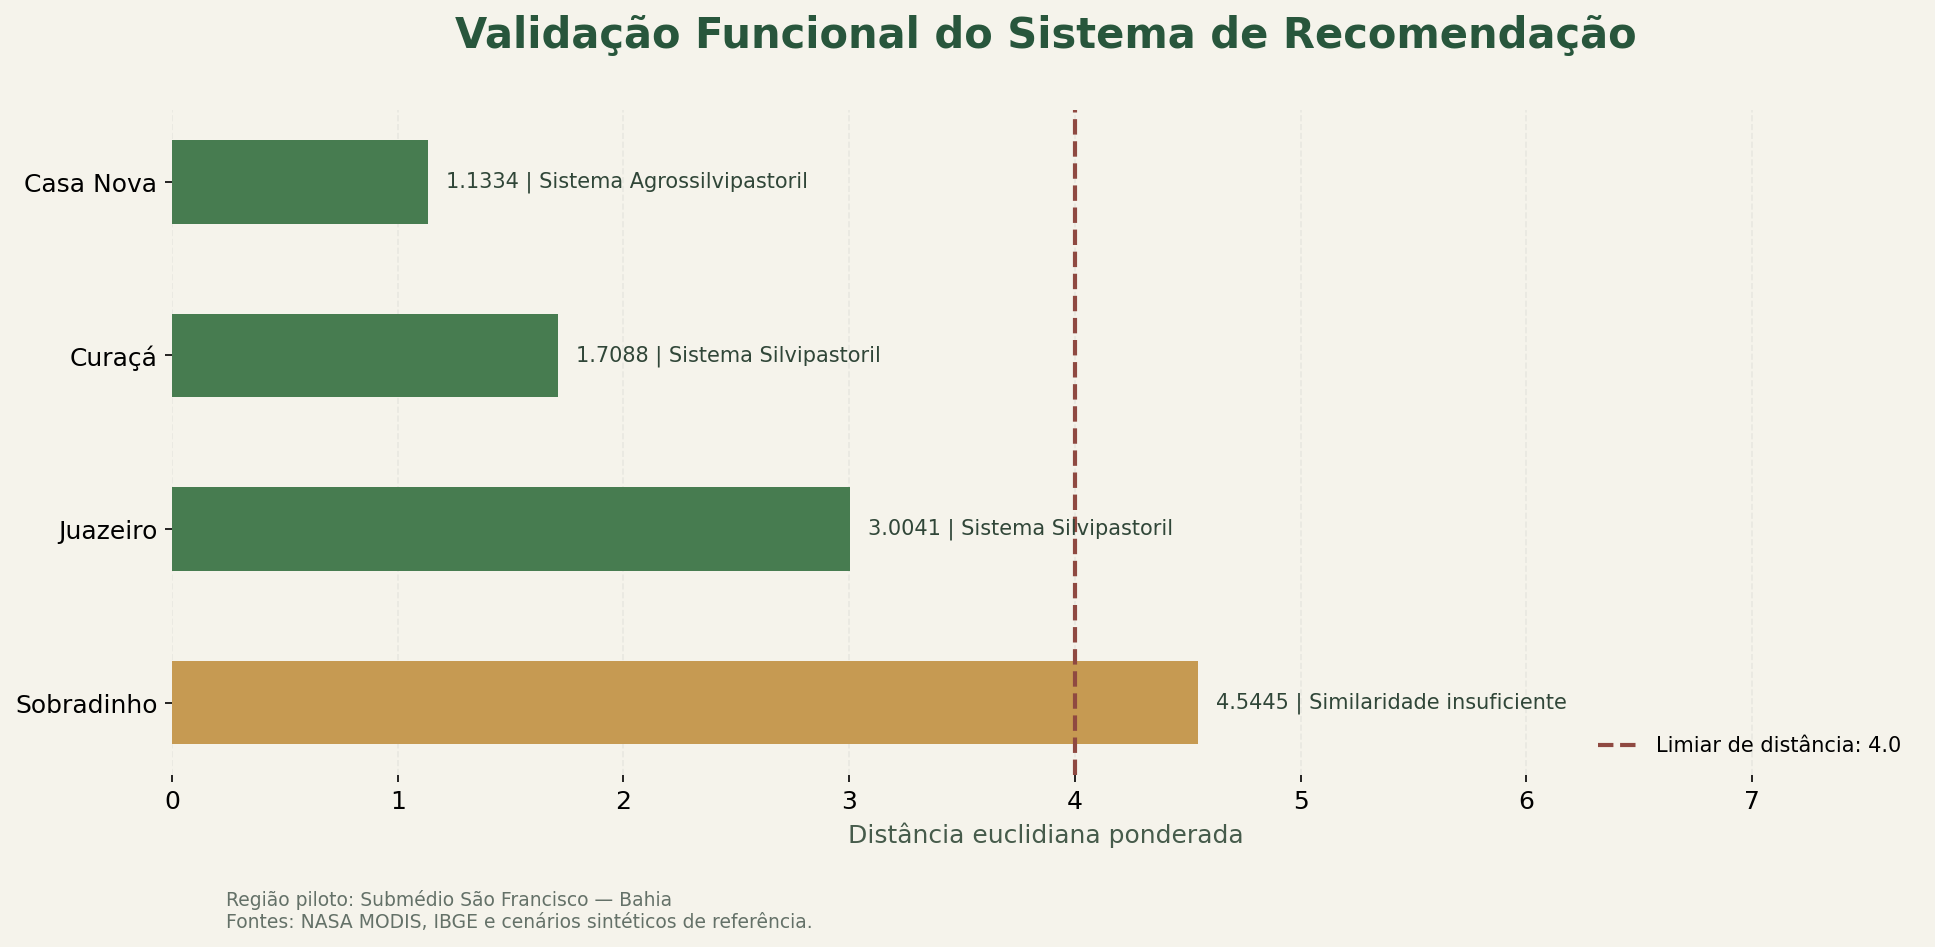

In [45]:

import matplotlib.pyplot as plt
import numpy as np

dados_plot = df_validacao.copy()

dados_plot["municipio"] = dados_plot["municipio"].replace({
    "Curaca": "Curaçá"
})

fundo = "#F5F3EB"
verde = "#477C50"
ocre = "#C69A52"

cores = [
    verde if status == "Recomendação gerada" else ocre
    for status in dados_plot["status"]
]

fig, ax = plt.subplots(figsize=(13, 6.5), dpi=150)

fig.patch.set_facecolor(fundo)
ax.set_facecolor(fundo)

barras = ax.barh(
    dados_plot["municipio"],
    dados_plot["menor_distancia"],
    color=cores,
    height=0.48
)

ax.axvline(
    DISTANCIA_MAXIMA,
    color="#8F4941",
    linestyle="--",
    linewidth=2,
    label=f"Limiar de distância: {DISTANCIA_MAXIMA}"
)

for barra, (_, linha) in zip(
    barras, dados_plot.iterrows()
):

    distancia = linha["menor_distancia"]

    if linha["status"] == "Recomendação gerada":

        rotulo = (
            f"{distancia:.4f} | "
            f"{linha['recomendacao']}"
        )

    else:

        rotulo = (
            f"{distancia:.4f} | "
            "Similaridade insuficiente"
        )

    ax.text(
        distancia + 0.08,
        barra.get_y() + barra.get_height() / 2,
        rotulo,
        va="center",
        fontsize=10,
        color="#304638"
    )

ax.invert_yaxis()

ax.set_xlim(
    0,
    max(
        dados_plot["menor_distancia"].max(),
        DISTANCIA_MAXIMA
    ) + 3.2
)

ax.set_title(
    "Validação Funcional do Sistema de Recomendação",
    fontsize=20,
    fontweight="bold",
    color="#28563C",
    pad=30
)

ax.set_xlabel(
    "Distância euclidiana ponderada",
    fontsize=12,
    color="#465B4B"
)

ax.tick_params(axis="both", labelsize=12)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

for borda in ax.spines.values():
    borda.set_visible(False)

ax.legend(
    loc="lower right",
    frameon=False
)

fig.text(
    0.12, 0.04,
    "Região piloto: Submédio São Francisco — Bahia\n"
    "Fontes: NASA MODIS, IBGE e cenários sintéticos de referência.",
    fontsize=9,
    color="#647168"
)

plt.tight_layout(rect=[0, 0.10, 1, 1])

plt.savefig(
    "Validacao_Final_KNN_Caatinga.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


In [46]:
from google.colab import files

files.download("Validacao_Final_KNN_Caatinga.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:

# ==========================================================
# ANÁLISE DE SENSIBILIDADE - IMPORTÂNCIA DO SOLO
# ==========================================================

from sklearn.base import clone

caracteristicas = extrair_caracteristicas(
    -9.6500, -40.3500
)

consulta = pd.DataFrame([caracteristicas])[FEATURES]

for peso_solo in [1.0, 1.5, 2.0]:

    preprocessador_teste = clone(preprocessador)

    preprocessador_teste.set_params(
        transformer_weights={
            "numericas": 1.0,
            "categoricas": peso_solo
        }
    )

    X_teste = preprocessador_teste.fit_transform(X)

    modelo_teste = NearestNeighbors(
        n_neighbors=K,
        metric="euclidean",
        algorithm="brute"
    )

    modelo_teste.fit(X_teste)

    consulta_teste = preprocessador_teste.transform(
        consulta
    )

    distancias, indices = modelo_teste.kneighbors(
        consulta_teste
    )

    vizinhos = casos.iloc[
        indices[0]
    ].copy().reset_index(drop=True)

    vizinhos["distancia"] = distancias[0]

    vizinhos, ranking = calcular_ranking(vizinhos)

    print("\n" + "=" * 60)
    print(f"FATOR DO SOLO: {peso_solo}")
    print("=" * 60)

    display(
        vizinhos[
            ["id_caso", "classe_solo", "solucao", "distancia"]
        ].round(4)
    )

    print("Vizinhos com a mesma classe de solo:")

    print(
        vizinhos["classe_solo"]
        .eq(caracteristicas["classe_solo"])
        .sum()
    )

    display(ranking.round(4))



FATOR DO SOLO: 1.0


,id_caso,classe_solo,solucao,distancia
0,IPF03,NEOSSOLO LITOLICO,IPF,2.2865
1,IPF01,LUVISSOLO,IPF,2.7608
2,IPF04,CAMBISSOLO,IPF,3.1543


Vizinhos com a mesma classe de solo:
0


,solucao,pontuacao,percentual,nome_solucao
0,IPF,1.1166,100.0,Sistema Silvipastoril



FATOR DO SOLO: 1.5


,id_caso,classe_solo,solucao,distancia
0,IPF03,NEOSSOLO LITOLICO,IPF,2.7800
1,IPF01,LUVISSOLO,IPF,3.1815
2,IPF04,CAMBISSOLO,IPF,3.5284


... (2 outputs left out)


FATOR DO SOLO: 2.0


,id_caso,classe_solo,solucao,distancia
0,IPF03,NEOSSOLO LITOLICO,IPF,3.3508
1,ILPF04,VERTISSOLO,ILPF,3.5801
2,IPF01,LUVISSOLO,IPF,3.6908


Vizinhos com a mesma classe de solo:
1


,solucao,pontuacao,percentual,nome_solucao
0,IPF,0.5694,67.0882,Sistema Silvipastoril
1,ILPF,0.2793,32.9118,Sistema Agrossilvipastoril


In [43]:
print(embrapa.columns.tolist())
display(embrapa)

['Classe de Solo (SiBCS)', 'Textura Predominante', 'Profundidade Efetiva', 'Fertilidade Natural', 'Drenagem Interna', 'Risco de Degradação', 'Principais Vulnerabilidades', 'Ocorrência Típica no Recorte', 'Aptidão e Manejo Recomendado', 'classe_normalizada']


,Classe de Solo (SiBCS),Textura Predominante,Profundidade Efetiva,Fertilidade Natural,Drenagem Interna,Risco de Degradação,Principais Vulnerabilidades,Ocorrência Típica no Recorte,Aptidão e Manejo Recomendado,classe_normalizada
0,Latossolos (Vermelhos e Vermelho-Amarelos),Média a argilosa (boa estrutura granular),Muito profundos (> 150–200 cm),Baixa a Média (geralmente distróficos),Bem a acentuadamente drenados,Baixo,Erosão laminar se mantidos descobertos; baixa ...,Tabuleiros e superfícies planas do interior (C...,Alta aptidão para fruticultura irrigada e past...,LATOSSOLO
1,Argissolos (Vermelho-Amarelos e Amarelos),Arenosa/média na superfície; argilosa em profu...,Profundos a moderadamente profundos (100–150 cm),Baixa a Média (eutróficos ou distróficos),Moderada a bem drenados,Moderado,Contraste textural favorece selamento superfic...,Áreas suavemente onduladas e perímetros irriga...,Boa aptidão para agricultura irrigada e pastag...,ARGISSOLO
2,Cambissolos (Háplicos),Média a argilosa (frequentemente siltosos),Pouco profundos a moderados (60–120 cm),Média a Alta (frequentemente eutróficos/carbon...,Moderada a boa,Moderado,"Selamento superficial, erosão em declives e ri...",Expressivos no Vale do Salitre e áreas calcári...,Muito utilizados na fruticultura irrigada (man...,CAMBISSOLO
3,Neossolos Flúvicos,Muito variável (camadas estratificadas de arei...,Profundos (> 120 cm),"Alta (eutróficos, ricos em nutrientes aluviais)",Imperfeita a moderada,Alto,Alto risco de salinização e sodificação sob ir...,"Planícies aluviais, várzeas e terraços ao long...","Alta produtividade para hortaliças, fruticultu...",NEOSSOLO FLUVICO
4,Vertissolos (Háplicos e Ebânicos),Muito argilosa (argilas expansivas 2:1),Moderadamente profundos (80–120 cm),"Muito Alta (eutróficos, elevada CTC)",Imperfeita a mal drenados,Alto,Fendas profundas na seca e alta plasticidade/p...,Manchas expressivas em Juazeiro (projetos Mand...,Mecanização restrita à faixa ideal de umidade;...,VERTISSOLO
5,Luvissolos (Crômicos),Média na superfície e argilosa no horizonte Bt...,Rasos a pouco profundos (50–100 cm),"Alta (eutróficos, ricos em Ca, Mg e K)",Moderada a imperfeita,Alto,Elevada erodibilidade superficial pela baixa p...,Depressão Sertaneja sobre embasamento cristali...,Restrição à mecanização intensiva; indicados p...,LUVISSOLO
6,Planossolos (Háplicos e Nátricos),Superfície arenosa/média com transição abrupta...,Rasos a pouco profundos (50–100 cm),Média a Alta (frequentemente com excesso de só...,Imperfeita a mal drenados,Muito Alto,"Baixíssima infiltração, encharcamento sazonal,...",Áreas de relevo plano a suave-ondulado em depr...,Inaptos para irrigação convencional; recomenda...,PLANOSSOLO
7,Neossolos Quartzarênicos,Arenosa (> 85% areia em todo o perfil),Muito profundos (> 150 cm),Muito Baixa (baixíssima retenção de água e nut...,Excessivamente drenados,Muito Alto,"Erosão eólica intensa, perda rápida de matéria...",Extensos campos de dunas continentais e áreas ...,Evitar revolvimento; priorizar preservação da ...,NEOSSOLO QUARTZARENICO
8,Neossolos Litólicos,"Variável (arenosa a média), com elevada pedreg...",Muito rasos (< 50 cm sobre rocha),Variável (limitada pelo reduzido volume de solo),Imperfeita a moderada (barrada pela rocha),Muito Alto,"Erosão severa, déficit hídrico extremo e proce...","Serras, morros residuais e pediplanos cristali...",Inaptos para lavouras mecanizadas; destinar à ...,NEOSSOLO LITOLICO
